# 04c - CatBoost Model

We train and tune CatBoost on `results/train.csv` using the shared 5-fold CV splits. `results/test.csv` is not used here.


In [1]:
# imports and 5-fold setup
import json
import sys
from pathlib import Path

sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from catboost import CatBoostClassifier
from sklearn.calibration import CalibrationDisplay
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    brier_score_loss,
    confusion_matrix,
    f1_score,
    fbeta_score,
    precision_recall_curve,
    roc_auc_score,
    roc_curve,
)

from src import evaluate, preprocess
from src.feature_sets import FEATURE_SETS, raw_input_cols

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)

df, _ = preprocess.load_train_data()
y = df["target"].to_numpy()
splits = evaluate.make_cv_splits(df)
print("train shape:", df.shape, "| folds:", len(splits))
print("feature sets:", {k: len(v) for k, v in FEATURE_SETS.items()})


train shape: (12378, 66) | folds: 5
feature sets: {'ada_like_7': 7, 'custom_10': 10, 'no_device_15': 15, 'practical_20': 20, 'top_30': 30, 'all_64': 64}


## 1. Feature Set Comparison

First we run a baseline CatBoost model (`iterations=400, depth=6, learning_rate=0.05`) on all 6 shared feature sets using the same 5 folds.


In [2]:
# 5-fold CV helper for catboost
def run_catboost_cv(cols, params):
    raw_cols = raw_input_cols(cols)
    oof = np.zeros(len(df))
    fold_aucs, fold_prs = [], []

    for tr, va in splits:
        prep = preprocess.build_preprocessor("catboost", cols, use_engineered=True)
        Xt_tr = prep.fit_transform(df.iloc[tr][raw_cols])
        Xt_va = prep.transform(df.iloc[va][raw_cols])
        cat_cols = prep.named_steps["prep"].cat_cols

        clf = CatBoostClassifier(
            **params,
            random_seed=evaluate.SEED,
            verbose=0,
            thread_count=-1,
            allow_writing_files=False,
        )
        clf.fit(Xt_tr, y[tr], cat_features=cat_cols)
        probs = clf.predict_proba(Xt_va)[:, 1]
        oof[va] = probs
        fold_aucs.append(float(roc_auc_score(y[va], probs)))
        fold_prs.append(float(average_precision_score(y[va], probs)))

    thr, m = evaluate.find_best_threshold(y, oof)
    y_pred = (oof >= thr).astype(int)
    m["f1"] = round(float(f1_score(y, y_pred, zero_division=0)), 4)
    m["brier"] = round(float(brier_score_loss(y, oof)), 4)
    m["auc_std"] = round(float(np.std(fold_aucs)), 4)
    m["pr_std"] = round(float(np.std(fold_prs)), 4)
    return m, oof, fold_aucs


base_params = {"iterations": 400, "depth": 6, "learning_rate": 0.05}
fs_rows = []
fs_oofs = {}

for name, cols in FEATURE_SETS.items():
    m, oof, _ = run_catboost_cv(cols, base_params)
    fs_oofs[name] = oof
    row = {
        "feature_set": name,
        "n_features": len(cols),
        "roc_auc": m["roc_auc"],
        "auc_std": m["auc_std"],
        "pr_auc": m["pr_auc"],
        "pr_std": m["pr_std"],
        "f2": m["f2"],
        "f1": m["f1"],
        "recall": m["recall"],
        "specificity": m["specificity"],
        "precision": m["precision"],
        "brier": m["brier"],
        "threshold": m["threshold"],
        "tp": m["tp"],
        "fp": m["fp"],
        "tn": m["tn"],
        "fn": m["fn"],
    }
    fs_rows.append(row)
    print(f"{name} ({len(cols)} cols): AUC={m['roc_auc']:.4f} +/- {m['auc_std']:.4f}, PR={m['pr_auc']:.4f}, F2={m['f2']:.4f}, Brier={m['brier']:.4f}")

fs_df = pd.DataFrame(fs_rows)
display(fs_df)


ada_like_7 (7 cols): AUC=0.7344 +/- 0.0076, PR=0.4894, F2=0.5886, Brier=0.1803


custom_10 (10 cols): AUC=0.7543 +/- 0.0105, PR=0.5252, F2=0.6306, Brier=0.1747


no_device_15 (15 cols): AUC=0.7595 +/- 0.0100, PR=0.5343, F2=0.6382, Brier=0.1734


practical_20 (20 cols): AUC=0.7613 +/- 0.0099, PR=0.5398, F2=0.6356, Brier=0.1729


top_30 (30 cols): AUC=0.7623 +/- 0.0115, PR=0.5423, F2=0.6453, Brier=0.1725


all_64 (64 cols): AUC=0.7611 +/- 0.0107, PR=0.5406, F2=0.6375, Brier=0.1727


,feature_set,n_features,roc_auc,auc_std,pr_auc,pr_std,f2,f1,recall,specificity,precision,brier,threshold,tp,fp,tn,fn
0,ada_like_7,7,0.7344,0.0076,0.4894,0.0120,0.5886,0.5378,0.6281,0.7023,0.4702,0.1803,0.360,2302,2594,6119,1363
1,custom_10,10,0.7543,0.0105,0.5252,0.0260,0.6306,0.5689,0.6797,0.7015,0.4892,0.1747,0.334,2491,2601,6112,1174
2,no_device_15,15,0.7595,0.0100,0.5343,0.0158,0.6382,0.5741,0.6895,0.7003,0.4918,0.1734,0.323,2527,2611,6102,1138
3,practical_20,20,0.7613,0.0099,0.5398,0.0159,0.6356,0.5723,0.6862,0.7006,0.4908,0.1729,0.325,2515,2609,6104,1150
4,top_30,30,0.7623,0.0115,0.5423,0.0195,0.6453,0.5795,0.6982,0.7007,0.4953,0.1725,0.320,2559,2608,6105,1106
5,all_64,64,0.7611,0.0107,0.5406,0.0162,0.6375,0.5735,0.6887,0.7001,0.4913,0.1727,0.324,2524,2613,6100,1141


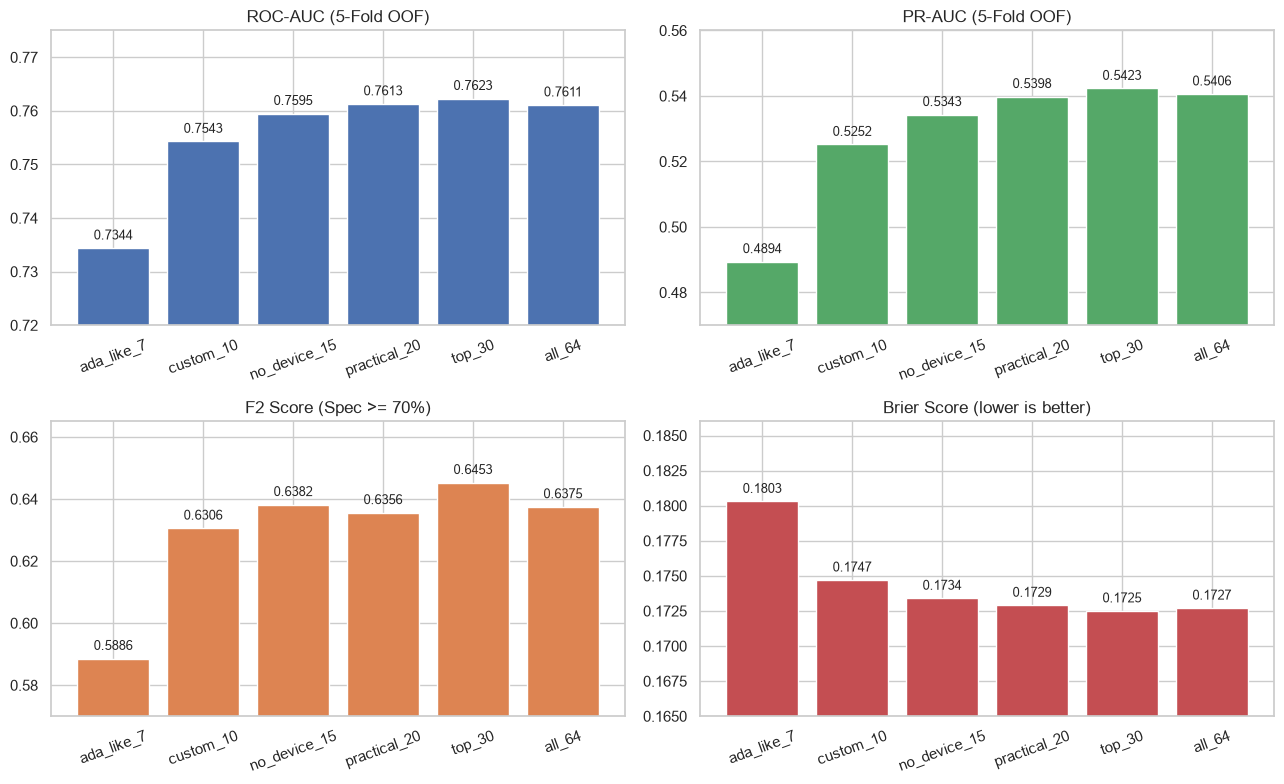

In [3]:
# bar charts for the 6 feature sets
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
metrics_to_plot = [
    ("roc_auc", "ROC-AUC (5-Fold OOF)", (0.72, 0.775), "#4c72b0"),
    ("pr_auc", "PR-AUC (5-Fold OOF)", (0.47, 0.56), "#55a868"),
    ("f2", "F2 Score (Spec >= 70%)", (0.57, 0.665), "#dd8452"),
    ("brier", "Brier Score (lower is better)", (0.165, 0.186), "#c44e52"),
]

for ax, (col, title, ylim, color) in zip(axes.ravel(), metrics_to_plot):
    bars = ax.bar(fs_df["feature_set"], fs_df[col], color=color)
    ax.set_title(title)
    ax.set_ylim(*ylim)
    ax.tick_params(axis="x", rotation=20)
    for b in bars:
        val = b.get_height()
        ax.text(
            b.get_x() + b.get_width() / 2,
            val + (ylim[1] - ylim[0]) * 0.02,
            f"{val:.4f}",
            ha="center",
            va="bottom",
            fontsize=9,
        )

plt.tight_layout()
plt.show()


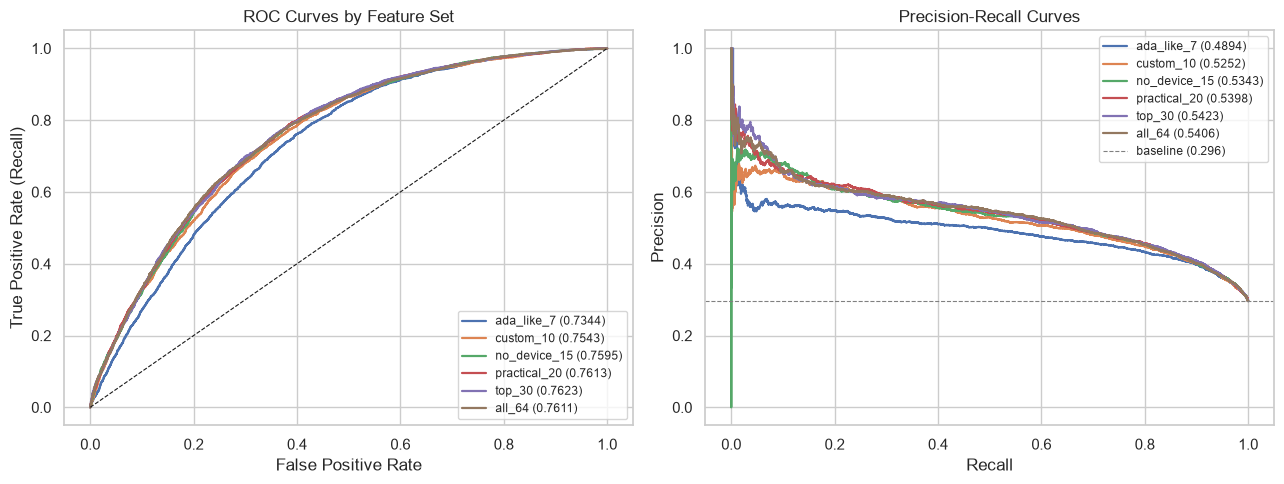

In [4]:
# ROC and PR curves for all 6 feature sets
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for row in fs_rows:
    name = row["feature_set"]
    oof = fs_oofs[name]
    fpr, tpr, _ = roc_curve(y, oof)
    prec, rec, _ = precision_recall_curve(y, oof)
    axes[0].plot(fpr, tpr, linewidth=1.6, label=f"{name} ({row['roc_auc']:.4f})")
    axes[1].plot(rec, prec, linewidth=1.6, label=f"{name} ({row['pr_auc']:.4f})")

axes[0].plot([0, 1], [0, 1], "k--", linewidth=0.8)
axes[0].set_title("ROC Curves by Feature Set")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate (Recall)")
axes[0].legend(fontsize=8.5, loc="lower right")

axes[1].axhline(y.mean(), color="grey", linestyle="--", linewidth=0.8, label=f"baseline ({y.mean():.3f})")
axes[1].set_title("Precision-Recall Curves")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].legend(fontsize=8.5, loc="upper right")

plt.tight_layout()
plt.show()


Going from `ada_like_7` (0.7344 AUC) to `custom_10` (0.7543 AUC) and `no_device_15` (0.7595 AUC) gives a clear jump even without blood pressure or waist tape. `practical_20` (0.7613) already edges out `all_64` (0.7611), and `top_30` gives the highest baseline score (0.7623 AUC, 0.6453 F2).


## 2. Hyperparameter Tuning

Next we try 8 parameter settings (`depth`, `learning_rate`, `l2_leaf_reg`, `iterations`) on `custom_10`, `practical_20`, and `top_30` across the same 5 folds.


In [5]:
# try 8 parameter settings across custom_10, practical_20, and top_30
param_grid = [
    {"label": "d4_lr03_l2_3",  "iterations": 700, "depth": 4, "learning_rate": 0.03, "l2_leaf_reg": 3},
    {"label": "d4_lr03_l2_10", "iterations": 700, "depth": 4, "learning_rate": 0.03, "l2_leaf_reg": 10},
    {"label": "d4_lr05_l2_3",  "iterations": 500, "depth": 4, "learning_rate": 0.05, "l2_leaf_reg": 3},
    {"label": "d5_lr03_l2_3",  "iterations": 600, "depth": 5, "learning_rate": 0.03, "l2_leaf_reg": 3},
    {"label": "d5_lr03_l2_10", "iterations": 600, "depth": 5, "learning_rate": 0.03, "l2_leaf_reg": 10},
    {"label": "d6_lr03_l2_3",  "iterations": 500, "depth": 6, "learning_rate": 0.03, "l2_leaf_reg": 3},
    {"label": "d6_lr03_l2_10", "iterations": 600, "depth": 6, "learning_rate": 0.03, "l2_leaf_reg": 10},
    {"label": "d7_lr03_l2_10", "iterations": 500, "depth": 7, "learning_rate": 0.03, "l2_leaf_reg": 10},
]

tune_sets = ["custom_10", "practical_20", "top_30"]
tune_rows = []
oof_store = {}

for set_name in tune_sets:
    cols = FEATURE_SETS[set_name]
    for item in param_grid:
        cfg = {k: v for k, v in item.items() if k != "label"}
        m, oof, fold_aucs = run_catboost_cv(cols, cfg)
        key = (set_name, item["label"])
        oof_store[key] = (m, oof, cfg, fold_aucs)
        tune_rows.append({
            "feature_set": set_name,
            "config": item["label"],
            "n_features": len(cols),
            **cfg,
            "roc_auc": m["roc_auc"],
            "auc_std": m["auc_std"],
            "pr_auc": m["pr_auc"],
            "pr_std": m["pr_std"],
            "f2": m["f2"],
            "f1": m["f1"],
            "recall": m["recall"],
            "specificity": m["specificity"],
            "precision": m["precision"],
            "brier": m["brier"],
            "threshold": m["threshold"],
        })
        print(f"{set_name} | {item['label']}: AUC={m['roc_auc']:.4f} +/- {m['auc_std']:.4f}, PR={m['pr_auc']:.4f}, F2={m['f2']:.4f}, Brier={m['brier']:.4f}")

tune_df = pd.DataFrame(tune_rows).sort_values(["roc_auc", "pr_auc", "f2"], ascending=False).reset_index(drop=True)
display(tune_df)


custom_10 | d4_lr03_l2_3: AUC=0.7571 +/- 0.0116, PR=0.5275, F2=0.6308, Brier=0.1739


custom_10 | d4_lr03_l2_10: AUC=0.7572 +/- 0.0113, PR=0.5281, F2=0.6329, Brier=0.1738


custom_10 | d4_lr05_l2_3: AUC=0.7563 +/- 0.0118, PR=0.5258, F2=0.6340, Brier=0.1741


custom_10 | d5_lr03_l2_3: AUC=0.7570 +/- 0.0108, PR=0.5273, F2=0.6307, Brier=0.1739


custom_10 | d5_lr03_l2_10: AUC=0.7570 +/- 0.0111, PR=0.5290, F2=0.6287, Brier=0.1738


custom_10 | d6_lr03_l2_3: AUC=0.7561 +/- 0.0110, PR=0.5269, F2=0.6335, Brier=0.1742


... (15 outputs left out)

top_30 | d6_lr03_l2_3: AUC=0.7656 +/- 0.0105, PR=0.5465, F2=0.6466, Brier=0.1713


top_30 | d6_lr03_l2_10: AUC=0.7640 +/- 0.0099, PR=0.5453, F2=0.6426, Brier=0.1718


top_30 | d7_lr03_l2_10: AUC=0.7635 +/- 0.0100, PR=0.5459, F2=0.6412, Brier=0.1718


,feature_set,config,n_features,iterations,depth,learning_rate,l2_leaf_reg,roc_auc,auc_std,pr_auc,pr_std,f2,f1,recall,specificity,precision,brier,threshold
0,top_30,d6_lr03_l2_3,30,500,6,0.03,3,0.7656,0.0105,0.5465,0.0169,0.6466,0.5806,0.6996,0.7011,0.4961,0.1713,0.324
1,top_30,d4_lr03_l2_10,30,700,4,0.03,10,0.7651,0.0094,0.5464,0.0169,0.6453,0.5794,0.6982,0.7006,0.4952,0.1714,0.325
2,practical_20,d4_lr03_l2_10,20,700,4,0.03,10,0.7647,0.0097,0.5452,0.0150,0.6416,0.5768,0.6936,0.7008,0.4937,0.1715,0.327
3,top_30,d5_lr03_l2_10,30,600,5,0.03,10,0.7644,0.0095,0.5484,0.0144,0.6461,0.5802,0.6990,0.7011,0.4959,0.1715,0.325
4,practical_20,d4_lr03_l2_3,20,700,4,0.03,3,0.7644,0.0098,0.5444,0.0144,0.6408,0.5759,0.6928,0.7001,0.4928,0.1717,0.327
5,top_30,d4_lr03_l2_3,30,700,4,0.03,3,0.7644,0.0101,0.5440,0.0155,0.6434,0.5782,0.6958,0.7009,0.4946,0.1717,0.325
6,practical_20,d5_lr03_l2_10,20,600,5,0.03,10,0.7641,0.0098,0.5440,0.0145,0.6438,0.5784,0.6963,0.7008,0.4947,0.1718,0.326
7,top_30,d6_lr03_l2_10,30,600,6,0.03,10,0.7640,0.0099,0.5453,0.0179,0.6426,0.5777,0.6947,0.7011,0.4944,0.1718,0.325
8,top_30,d5_lr03_l2_3,30,600,5,0.03,3,0.7637,0.0101,0.5449,0.0141,0.6418,0.5769,0.6939,0.7007,0.4937,0.1719,0.326
9,top_30,d4_lr05_l2_3,30,500,4,0.05,3,0.7636,0.0093,0.5442,0.0146,0.6471,0.5807,0.7004,0.7006,0.4959,0.1720,0.322


,feature_set,best_config,base_auc,tuned_auc,auc_gain,base_pr,tuned_pr,base_f2,tuned_f2,f2_gain,tuned_brier
0,custom_10,d4_lr03_l2_10,0.7543,0.7572,0.0029,0.5252,0.5281,0.6306,0.6329,0.0023,0.1738
1,practical_20,d4_lr03_l2_10,0.7613,0.7647,0.0034,0.5398,0.5452,0.6356,0.6416,0.0060,0.1715
2,top_30,d6_lr03_l2_3,0.7623,0.7656,0.0033,0.5423,0.5465,0.6453,0.6466,0.0013,0.1713


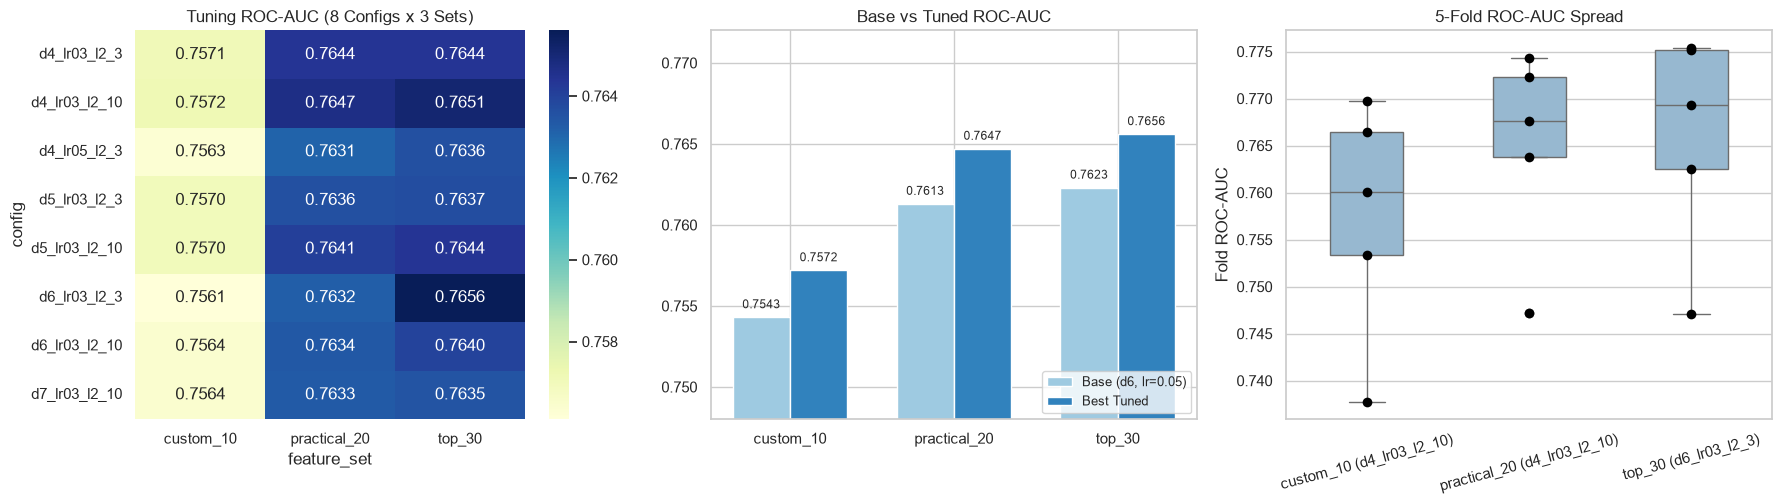

In [6]:
# compare base vs best tuned score for each of the 3 sets
best_per_set = (
    tune_df.sort_values(["roc_auc", "pr_auc", "f2"], ascending=False)
    .groupby("feature_set", as_index=False)
    .first()
)
base_lookup = fs_df.set_index("feature_set")

comp_summary = []
for set_name in tune_sets:
    brow = best_per_set.loc[best_per_set["feature_set"] == set_name].iloc[0]
    base_r = base_lookup.loc[set_name]
    comp_summary.append({
        "feature_set": set_name,
        "best_config": brow["config"],
        "base_auc": base_r["roc_auc"],
        "tuned_auc": brow["roc_auc"],
        "auc_gain": round(float(brow["roc_auc"] - base_r["roc_auc"]), 4),
        "base_pr": base_r["pr_auc"],
        "tuned_pr": brow["pr_auc"],
        "base_f2": base_r["f2"],
        "tuned_f2": brow["f2"],
        "f2_gain": round(float(brow["f2"] - base_r["f2"]), 4),
        "tuned_brier": brow["brier"],
    })
comp_sum_df = pd.DataFrame(comp_summary)
display(comp_sum_df)

# heatmap, base vs tuned bars, and fold spread
fig, axes = plt.subplots(1, 3, figsize=(18, 5.2))

piv = tune_df.pivot(index="config", columns="feature_set", values="roc_auc")[tune_sets]
piv = piv.reindex([x["label"] for x in param_grid])
sns.heatmap(piv, annot=True, fmt=".4f", cmap="YlGnBu", ax=axes[0])
axes[0].set_title("Tuning ROC-AUC (8 Configs x 3 Sets)")

x_idx = np.arange(len(tune_sets))
w = 0.35
b1 = axes[1].bar(x_idx - w / 2, comp_sum_df["base_auc"], width=w, label="Base (d6, lr=0.05)", color="#9ecae1")
b2 = axes[1].bar(x_idx + w / 2, comp_sum_df["tuned_auc"], width=w, label="Best Tuned", color="#3182bd")
axes[1].set_xticks(x_idx)
axes[1].set_xticklabels(tune_sets)
axes[1].set_ylim(0.748, 0.772)
axes[1].set_title("Base vs Tuned ROC-AUC")
axes[1].legend(loc="lower right", fontsize=9)
for b in list(b1) + list(b2):
    val = b.get_height()
    axes[1].text(b.get_x() + b.get_width() / 2, val + 0.0004, f"{val:.4f}", ha="center", va="bottom", fontsize=8.5)

fold_plot_rows = []
for set_name in tune_sets:
    brow = best_per_set.loc[best_per_set["feature_set"] == set_name].iloc[0]
    _, _, _, f_aucs = oof_store[(set_name, brow["config"])]
    label_txt = f"{set_name} ({brow['config']})"
    for fold_i, v in enumerate(f_aucs, start=1):
        fold_plot_rows.append({"model_set": label_txt, "fold": fold_i, "fold_auc": v})
fold_plot_df = pd.DataFrame(fold_plot_rows)

sns.boxplot(data=fold_plot_df, x="model_set", y="fold_auc", ax=axes[2], width=0.45, color="#8ebad9")
sns.stripplot(data=fold_plot_df, x="model_set", y="fold_auc", ax=axes[2], color="black", size=7, jitter=False)
axes[2].tick_params(axis="x", rotation=15)
axes[2].set_title("5-Fold ROC-AUC Spread")
axes[2].set_xlabel("")
axes[2].set_ylabel("Fold ROC-AUC")

plt.tight_layout()
plt.show()


Lowering `learning_rate` to 0.03 helped on all three feature sets. `custom_10` moved up to 0.7572 AUC, `practical_20` reached 0.7647 AUC and 0.6416 F2, and `top_30` gave our best overall result with 0.7656 AUC, 0.5465 PR-AUC, 0.6466 F2, and 0.1713 Brier (`depth=6, learning_rate=0.03, l2_leaf_reg=3, iterations=500`).


## 3. Calibration, Threshold, and Referral Rates

We use our best setting (`top_30` with `depth=6, learning_rate=0.03, l2_leaf_reg=3, iterations=500`) to check probability calibration, threshold choice (`specificity >= 0.70`), confusion matrix, and fixed referral rates (`20%`, `30%`, `40%`).


,variant,brier,roc_auc,pr_auc,threshold,f2,recall,specificity,precision
0,Raw CatBoost,0.1713,0.7656,0.5465,0.324,0.6466,0.6996,0.7011,0.4961
1,Platt scaling (sigmoid),0.1713,0.7654,0.5457,0.325,0.6460,0.6990,0.7008,0.4956


[Best CatBoost (top_30, d6_lr03_l2_3)]
  ROC-AUC: 0.7656 | PR-AUC: 0.5465 | F2: 0.6466 | Thr: 0.3240
  Recall: 0.6996 | Specificity: 0.7011 | Precision: 0.4961 | TP=2564 FP=2604 TN=6109 FN=1101


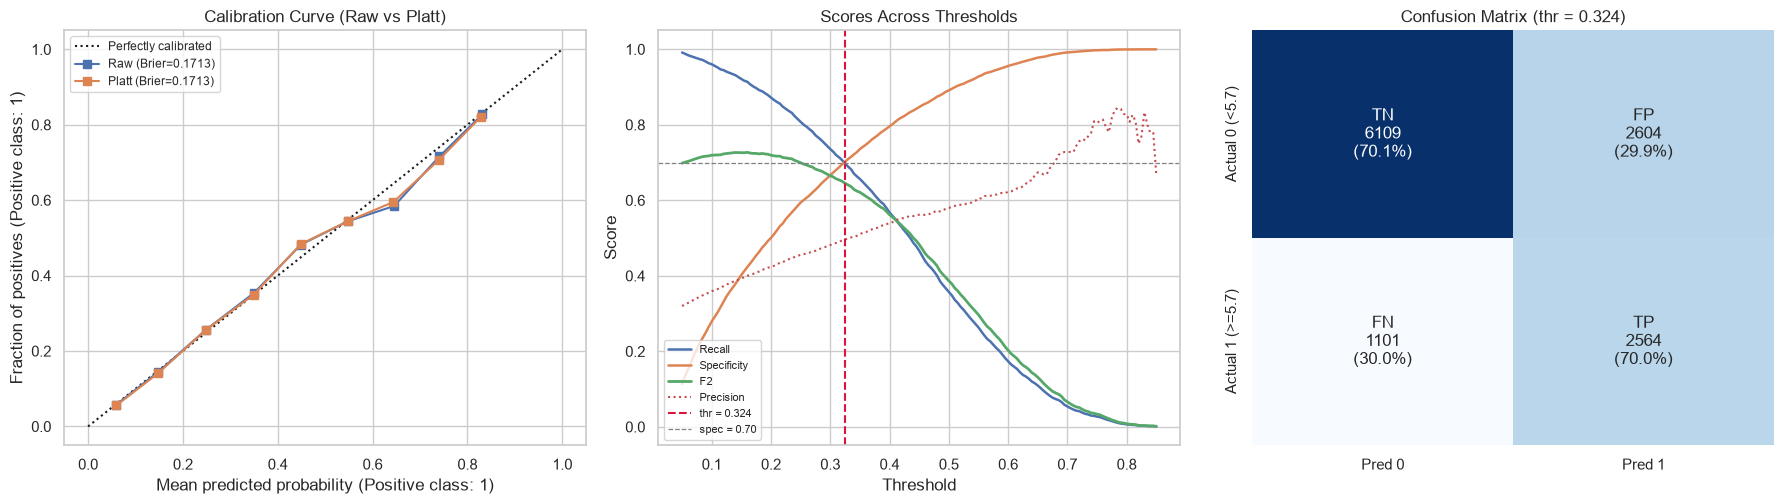

In [7]:
# compare raw probabilities with fold-by-fold platt scaling
best_set = "top_30"
best_label = "d6_lr03_l2_3"
best_m, best_oof, best_params, best_fold_aucs = oof_store[(best_set, best_label)]

platt_oof = np.zeros(len(df))
eps = 1e-6
clipped = np.clip(best_oof, eps, 1.0 - eps)
logits = np.log(clipped / (1.0 - clipped)).reshape(-1, 1)

for tr, va in splits:
    cal = LogisticRegression()
    cal.fit(logits[tr], y[tr])
    platt_oof[va] = cal.predict_proba(logits[va])[:, 1]

raw_brier = round(float(brier_score_loss(y, best_oof)), 4)
platt_brier = round(float(brier_score_loss(y, platt_oof)), 4)
platt_thr, platt_m = evaluate.find_best_threshold(y, platt_oof)

cal_comp_df = pd.DataFrame([
    {
        "variant": "Raw CatBoost",
        "brier": raw_brier,
        "roc_auc": best_m["roc_auc"],
        "pr_auc": best_m["pr_auc"],
        "threshold": best_m["threshold"],
        "f2": best_m["f2"],
        "recall": best_m["recall"],
        "specificity": best_m["specificity"],
        "precision": best_m["precision"],
    },
    {
        "variant": "Platt scaling (sigmoid)",
        "brier": platt_brier,
        "roc_auc": platt_m["roc_auc"],
        "pr_auc": platt_m["pr_auc"],
        "threshold": platt_m["threshold"],
        "f2": platt_m["f2"],
        "recall": platt_m["recall"],
        "specificity": platt_m["specificity"],
        "precision": platt_m["precision"],
    },
])
display(cal_comp_df)
evaluate.print_metrics(f"Best CatBoost ({best_set}, {best_label})", best_m)

# calibration plot, threshold curve, and confusion matrix
fig, axes = plt.subplots(1, 3, figsize=(18, 5.2))

CalibrationDisplay.from_predictions(
    y, best_oof, n_bins=10, name=f"Raw (Brier={raw_brier:.4f})", ax=axes[0]
)
CalibrationDisplay.from_predictions(
    y, platt_oof, n_bins=10, name=f"Platt (Brier={platt_brier:.4f})", ax=axes[0]
)
axes[0].set_title("Calibration Curve (Raw vs Platt)")
axes[0].legend(loc="upper left", fontsize=8.5)

grid_t = np.linspace(0.05, 0.85, 161)
rec_l, spec_l, prec_l, f2_l = [], [], [], []
for t in grid_t:
    yp = (best_oof >= t).astype(int)
    tn_i, fp_i, fn_i, tp_i = confusion_matrix(y, yp, labels=[0, 1]).ravel()
    rec_l.append(tp_i / (tp_i + fn_i))
    spec_l.append(tn_i / (tn_i + fp_i))
    prec_l.append(tp_i / (tp_i + fp_i) if (tp_i + fp_i) > 0 else 0.0)
    f2_l.append(fbeta_score(y, yp, beta=evaluate.F_BETA, zero_division=0))

axes[1].plot(grid_t, rec_l, label="Recall", linewidth=1.8)
axes[1].plot(grid_t, spec_l, label="Specificity", linewidth=1.8)
axes[1].plot(grid_t, f2_l, label="F2", linewidth=2.0)
axes[1].plot(grid_t, prec_l, label="Precision", linewidth=1.5, linestyle=":")
axes[1].axvline(best_m["threshold"], color="crimson", linestyle="--", label=f"thr = {best_m['threshold']:.3f}")
axes[1].axhline(0.70, color="grey", linestyle="--", linewidth=0.9, label="spec = 0.70")
axes[1].set_title("Scores Across Thresholds")
axes[1].set_xlabel("Threshold")
axes[1].set_ylabel("Score")
axes[1].legend(fontsize=8, loc="lower left")

cm = np.array([[best_m["tn"], best_m["fp"]], [best_m["fn"], best_m["tp"]]])
cm_pct = cm / cm.sum(axis=1, keepdims=True) * 100.0
annot = np.array([
    [f"TN\n{cm[0, 0]}\n({cm_pct[0, 0]:.1f}%)", f"FP\n{cm[0, 1]}\n({cm_pct[0, 1]:.1f}%)"],
    [f"FN\n{cm[1, 0]}\n({cm_pct[1, 0]:.1f}%)", f"TP\n{cm[1, 1]}\n({cm_pct[1, 1]:.1f}%)"],
])
sns.heatmap(
    cm,
    annot=annot,
    fmt="",
    cmap="Blues",
    cbar=False,
    xticklabels=["Pred 0", "Pred 1"],
    yticklabels=["Actual 0 (<5.7)", "Actual 1 (>=5.7)"],
    ax=axes[2],
)
axes[2].set_title(f"Confusion Matrix (thr = {best_m['threshold']:.3f})")

plt.tight_layout()
plt.show()


,referral_rate,n_referred,cutoff_prob,recall,specificity,precision,f2,tp,fp,tn,fn
0,0.2,2476,0.4856,0.3853,0.8779,0.5703,0.4120,1412,1064,7649,2253
1,0.3,3713,0.4079,0.5514,0.8058,0.5443,0.5500,2021,1692,7021,1644
2,0.4,4951,0.3365,0.6786,0.7172,0.5023,0.6341,2487,2464,6249,1178


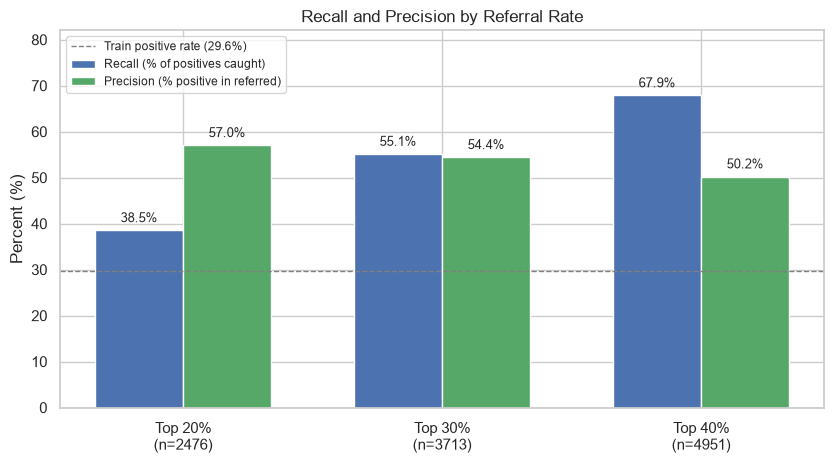

In [8]:
# check top 20%, 30%, and 40% highest-risk groups
referral_rows = []
order = np.argsort(-best_oof)
n_total = len(y)
n_pos = int(y.sum())
n_neg = int((y == 0).sum())

for rate in [0.20, 0.30, 0.40]:
    k = int(round(n_total * rate))
    top_idx = order[:k]
    y_ref = np.zeros_like(y)
    y_ref[top_idx] = 1
    cutoff = float(best_oof[top_idx[-1]])
    tp_r = int(((y == 1) & (y_ref == 1)).sum())
    fp_r = int(((y == 0) & (y_ref == 1)).sum())
    tn_r = int(((y == 0) & (y_ref == 0)).sum())
    fn_r = int(((y == 1) & (y_ref == 0)).sum())
    referral_rows.append({
        "referral_rate": rate,
        "n_referred": k,
        "cutoff_prob": round(cutoff, 4),
        "recall": round(tp_r / n_pos, 4),
        "specificity": round(tn_r / n_neg, 4),
        "precision": round(tp_r / k, 4),
        "f2": round(float(fbeta_score(y, y_ref, beta=evaluate.F_BETA, zero_division=0)), 4),
        "tp": tp_r,
        "fp": fp_r,
        "tn": tn_r,
        "fn": fn_r,
    })

ref_df = pd.DataFrame(referral_rows)
display(ref_df)

# plot recall and precision for the 3 referral budgets
fig, ax = plt.subplots(figsize=(8.5, 4.8))
x = np.arange(len(ref_df))
w = 0.34
b_rec = ax.bar(x - w / 2, ref_df["recall"] * 100, width=w, label="Recall (% of positives caught)", color="#4c72b0")
b_prc = ax.bar(x + w / 2, ref_df["precision"] * 100, width=w, label="Precision (% positive in referred)", color="#55a868")
ax.axhline(y.mean() * 100, color="grey", linestyle="--", linewidth=1.0, label=f"Train positive rate ({y.mean()*100:.1f}%)")
ax.set_xticks(x)
ax.set_xticklabels([f"Top {int(r*100)}%\n(n={n})" for r, n in zip(ref_df["referral_rate"], ref_df["n_referred"])])
ax.set_ylim(0, 82)
ax.set_ylabel("Percent (%)")
ax.set_title("Recall and Precision by Referral Rate")
ax.legend(loc="upper left", fontsize=8.5)

for b in list(b_rec) + list(b_prc):
    val = b.get_height()
    ax.text(b.get_x() + b.get_width() / 2, val + 1.2, f"{val:.1f}%", ha="center", va="bottom", fontsize=9)

plt.tight_layout()
plt.show()


Raw CatBoost probabilities already give `Brier = 0.1713`, which matches fold-by-fold Platt scaling (`0.1713`), so we keep the raw probabilities directly. At `threshold = 0.324`, specificity stays at `70.1%` (`6,109 / 8,713`) and recall is `70.0%` (`2,564 / 3,665`). Sending only the top `20%`, `30%`, or `40%` highest-risk people for an HbA1c test catches `38.5%`, `55.1%`, and `67.9%` of positive cases.


## 4. Save Experiment Outputs

Save out-of-fold predictions (`experiments/catboost_oof.csv`) and CV summary metrics (`experiments/catboost_cv.json`) in the shared format so we can compare LogReg, RF, and CatBoost side by side in the next step.


In [9]:
# save OOF predictions and CV summary json
exp_dir = Path("../experiments")
exp_dir.mkdir(exist_ok=True)

oof_out = df[["cycle", "seqn", "target"]].copy()
oof_out["oof_prob"] = np.round(best_oof, 6)
oof_path = exp_dir / "catboost_oof.csv"
oof_out.to_csv(oof_path, index=False)

cv_summary = {
    "model": "catboost",
    "best_feature_set": best_set,
    "features": FEATURE_SETS[best_set],
    "best_params": best_params,
    "best_metrics": best_m,
    "feature_set_comparison": fs_df.to_dict(orient="records"),
    "tuning_results": tune_df.to_dict(orient="records"),
    "referral_table": ref_df.to_dict(orient="records"),
}
json_path = exp_dir / "catboost_cv.json"
json_path.write_text(json.dumps(cv_summary, indent=2) + "\n", encoding="utf-8")

print("saved:", oof_path, oof_out.shape)
print("saved:", json_path, "| keys:", list(cv_summary.keys()))


saved: ../experiments/catboost_oof.csv (12378, 4)
saved: ../experiments/catboost_cv.json | keys: ['model', 'best_feature_set', 'features', 'best_params', 'best_metrics', 'feature_set_comparison', 'tuning_results', 'referral_table']
